(119390, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  mea

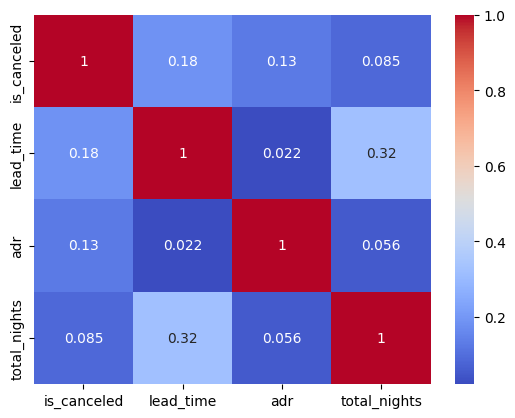

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

# 1. Import & explore
# Fixed the unexpected indentation and corrected the read_csv call
path = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(path)
print(df.shape)
df.info()
print(df.isnull().sum())

# 2. Cleaning
df["children"] = df["children"].fillna(0)                     # missing values
df["country"] = df["country"].fillna(df["country"].mode()[0])
df["children"] = df["children"].astype(int)                   # type conversion
df = df.drop_duplicates()                                     # duplicates
df = df[(df.adults + df.children + df.babies) > 0]            # noise
df = df[df.adr >= 0]

# 3. Transformation
df["total_nights"] = df.stays_in_weekend_nights + df.stays_in_week_nights
df["lead_group"] = pd.cut(df.lead_time, [-1, 30, 90, 365, 800],
                          labels=["Short", "Medium", "Long", "Very Long"])   # binning
df["lead_norm"] = (df.lead_time - df.lead_time.min()) / (df.lead_time.max() - df.lead_time.min())  # normalization
df["hotel_code"] = df["hotel"].map({"City Hotel": 0, "Resort Hotel": 1})     # encoding
enc = pd.get_dummies(df["customer_type"])                                    # one-hot

# 4. Summary & correlation
print(df.describe())
sns.heatmap(df[["is_canceled", "lead_time", "adr", "total_nights"]].corr(),
            annot=True, cmap="coolwarm")
plt.show()

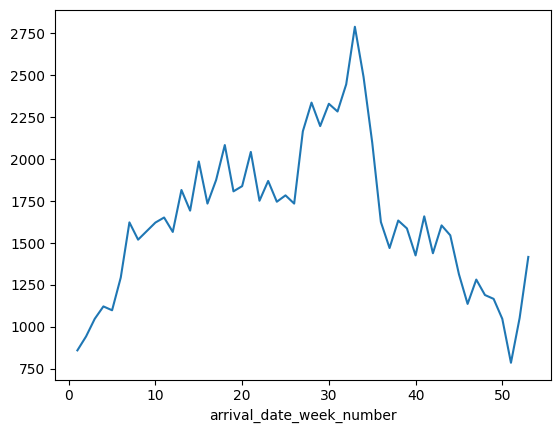

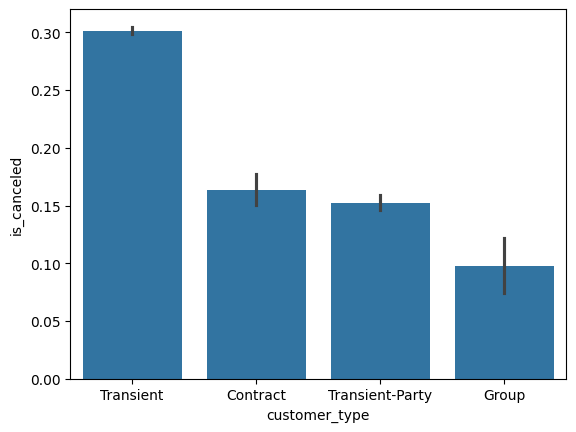

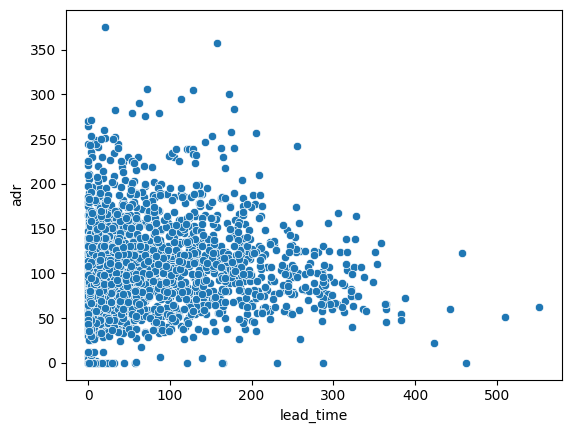

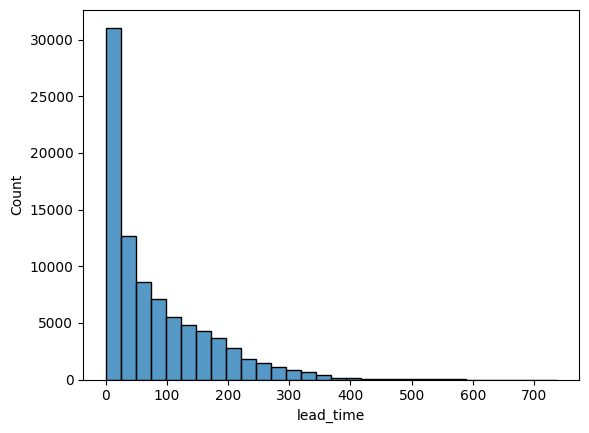

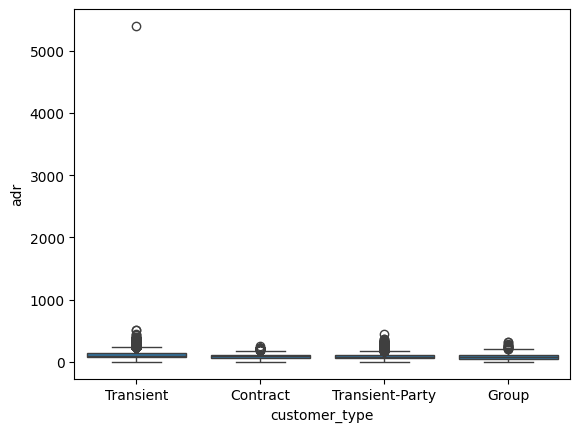

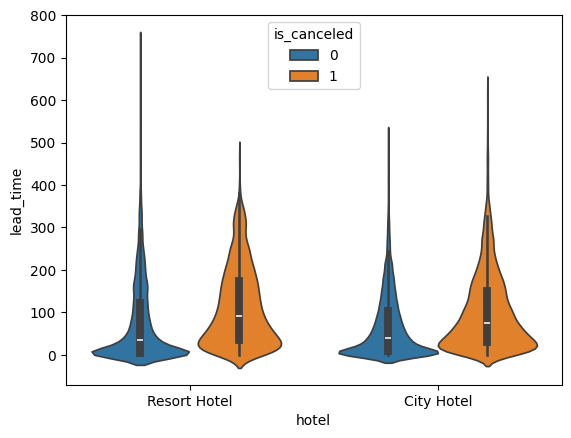

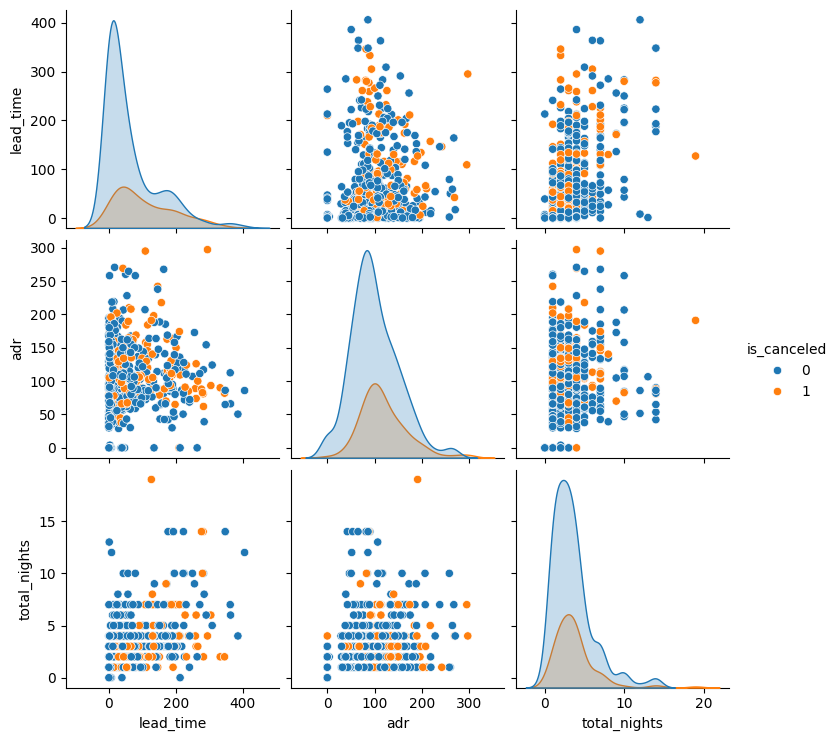

In [ ]:
# 5. Basic plots
df.groupby("arrival_date_week_number").size().plot()            # line (seasonal trend)
plt.show()
sns.barplot(x="customer_type", y="is_canceled", data=df)        # bar
plt.show()
sns.scatterplot(x="lead_time", y="adr", data=df.sample(2000))   # scatter
plt.show()
sns.histplot(df.lead_time, bins=30)                             # histogram
plt.show()

# 6. Advanced plots
sns.boxplot(x="customer_type", y="adr", data=df)                # box
plt.show()
sns.violinplot(x="hotel", y="lead_time", hue="is_canceled", data=df)   # violin
plt.show()
sns.pairplot(df[["lead_time", "adr", "total_nights", "is_canceled"]].sample(500),
             hue="is_canceled")                                 # pair plot
plt.show()

import plotly.express as px                                     # interactive
d = df.groupby("customer_type", as_index=False).is_canceled.mean()
px.bar(d, x="customer_type", y="is_canceled").show()

# 7. Dashboard (Plotly Dash)
# Commented out because running a local web server with app.run() blocks the Colab kernel.
# from dash import Dash, dcc, html, Input, Output
# app = Dash(__name__)
# app.layout = html.Div([
#     dcc.Dropdown(df.hotel.unique(), "City Hotel", id="h"),      # filter
#     dcc.Graph(id="g")])
#
# @app.callback(Output("g", "figure"), Input("h", "value"))
# def update(h):
#     d = df[df.hotel == h].groupby("customer_type", as_index=False).is_canceled.mean()
#     return px.bar(d, x="customer_type", y="is_canceled")
#
# app.run(jupyter_mode="inline") # Use jupyter_mode="inline" if you install and configure jupyter-dash